# Linear Regression Lab Assignment
**Dataset:** Diabetes (scikit-learn)

## Part A — Exploratory Data Analysis
### 1. Load and Inspect the Dataset
#### dataset built in sklearn
#### all values are standardized
#### goal is to measure the disease progression one year after base measurement. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TEST_SIZE = 0.20

In [2]:
data = load_diabetes()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target
df.head()
# 442 patiens, 10 features each
# age sex bmi bp sum(cholesterol) , low density lipoproteins , High-density lipoproteins, Total cholesterol / HDL ratio
# Possibly log of serum triglycerides level , Blood sugar level

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (442, 11)
Columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [5]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [6]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


### 2. Distribution of Target Variable

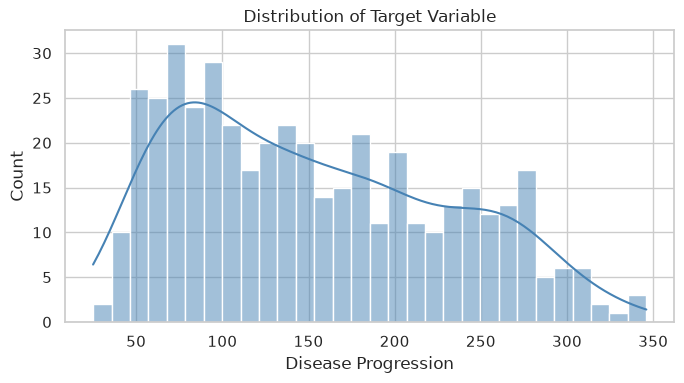

Skewness: 0.4406
The distribution is slight positive skew.


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["target"], kde=True, bins=30, color="steelblue", ax=ax) # kde adds the smooth lien showing overall shape
ax.set_title("Distribution of Target Variable")
ax.set_xlabel("Disease Progression")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

skew = df["target"].skew()
print(f"Skewness: {skew:.4f}")
print("The distribution is slight positive skew.")
# skewness is how symmetric the distribution is. if it has a tail or not

### 3. Correlation Analysis

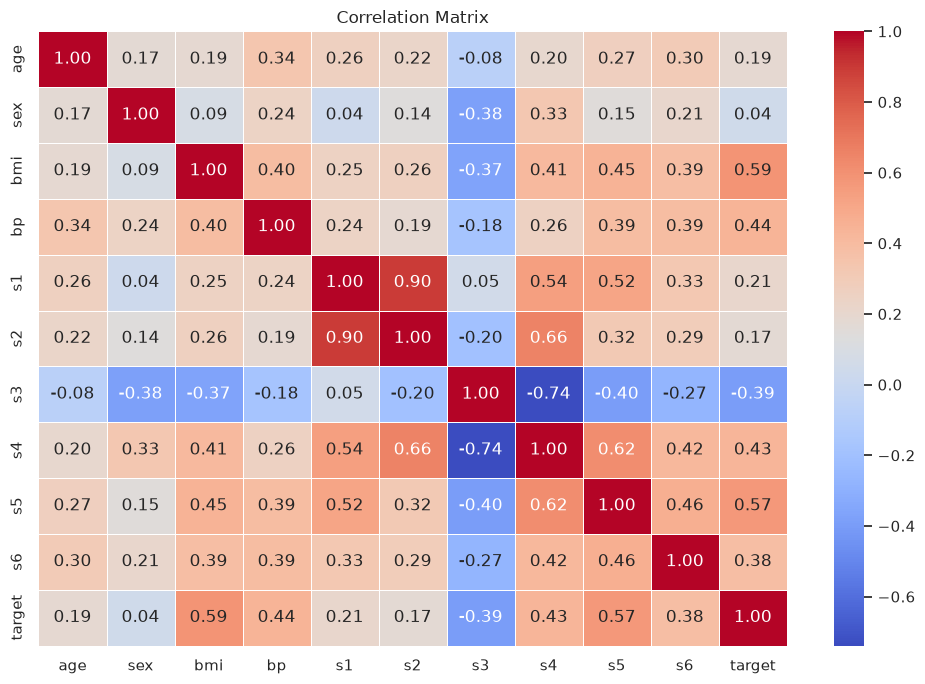

In [8]:
corr_matrix = df.corr()
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [9]:
target_corr = corr_matrix["target"].drop("target").sort_values(key=abs, ascending=False)
print("Feature correlations with target (sorted by absolute value):")
print(target_corr.to_string())

best_feature = target_corr.index[0]
print(f"\nStrongest absolute correlation: '{best_feature}' ({target_corr[best_feature]:.4f})")

Feature correlations with target (sorted by absolute value):
bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s3    -0.394789
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062

Strongest absolute correlation: 'bmi' (0.5865)


## Part B — Simple Linear Regression
### 1. Select One Predictor

In [10]:
X_simple = df[[best_feature]].values
y = df["target"].values
print(f"Selected predictor: {best_feature}")

Selected predictor: bmi


### 2. Hypothesis Equation

$$y = \beta_0 + \beta_1 X + \varepsilon$$

- **β₀**: intercept — value of y when X = 0 (where the line starts)
- **β₁**: slope — change in y per unit increase in X
- **ε**: error term — unexplained noise

### 3. Train the Model

In [11]:
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
slr = LinearRegression()
slr.fit(X_train_s, y_train)
print(f"Train: {X_train_s.shape[0]} samples | Test: {X_test_s.shape[0]} samples")

Train: 353 samples | Test: 89 samples


### 4. Report Coefficients

In [12]:
b0_s = slr.intercept_
b1_s = slr.coef_[0] # gives beta 1  aka the slope
print(f"Intercept (β₀): {b0_s:.4f}")
print(f"Slope (β₁):     {b1_s:.4f}")
print(f"Fitted equation: target = {b0_s:.4f} + {b1_s:.4f} × {best_feature}")

Intercept (β₀): 152.0034
Slope (β₁):     998.5777
Fitted equation: target = 152.0034 + 998.5777 × bmi


### 5. Scatter Plot with Regression Line

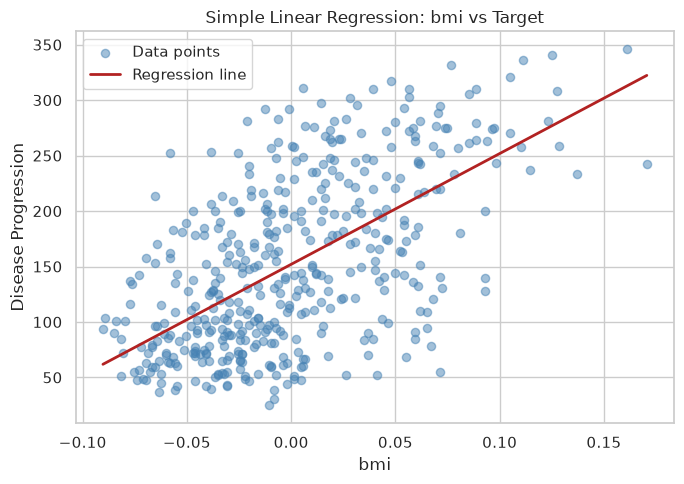

In [13]:
x_range = np.linspace(X_simple.min(), X_simple.max(), 200).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_simple, y, alpha=0.5, color="steelblue", s=35, label="Data points")
ax.plot(x_range, slr.predict(x_range), color="firebrick", linewidth=2, label="Regression line")
ax.set_title(f"Simple Linear Regression: {best_feature} vs Target")
ax.set_xlabel(best_feature)
ax.set_ylabel("Disease Progression")
ax.legend()
plt.tight_layout()
plt.show()

### 6. Interpret the Slope

In [ ]:
print(f"A one-unit increase in '{best_feature}' is associated with a {b1_s:.2f}-unit"
      f" change in predicted disease progression.")
      # If BMI increases by 1 unit, the model's predicted disease progression increases by approximately 998.58 units

A one-unit increase in 'bmi' is associated with a 998.58-unit change in predicted disease progression.


### 7. Evaluate Simple Regression

In [ ]:
y_pred_s = slr.predict(X_test_s)
r2_s  = r2_score(y_test, y_pred_s)
mse_s = mean_squared_error(y_test, y_pred_s)
rmse_s = np.sqrt(mse_s)
print(f"R²:   {r2_s:.4f}") # how much variation in the target is explained by the model. 0 -> bad , 1 -> good
print(f"MSE:  {mse_s:.4f}") # avg diff between actual and predicted 1/n sum of (yactual- ypred)^2
print(f"RMSE: {rmse_s:.4f}") # usefull because it is in the same unit as our target values

R²:   0.2334
MSE:  4061.8259
RMSE: 63.7325


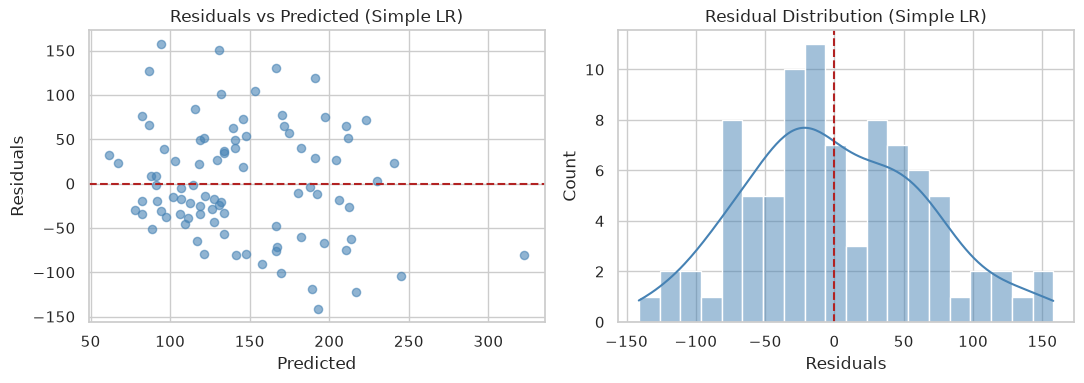

Residuals are scattered randomly around zero with no strong pattern, though some spread remains.


In [ ]:
residuals_s = y_test - y_pred_s
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_pred_s, residuals_s, alpha=0.6, color="steelblue", s=35)
axes[0].axhline(0, color="firebrick", linestyle="--")
axes[0].set_title("Residuals vs Predicted (Simple LR)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Residuals")
sns.histplot(residuals_s, kde=True, bins=20, color="steelblue", ax=axes[1])
axes[1].axvline(0, color="firebrick", linestyle="--")
axes[1].set_title("Residual Distribution (Simple LR)")
axes[1].set_xlabel("Residuals")
plt.tight_layout()
plt.show()
print("Residuals are scattered randomly around zero with no strong pattern, though some spread remains.")
# No strong visible pattern
# Large residuals exist
# vely low R² = 0.2334

## Part C — Multiple Linear Regression
### 1. Select Predictors

In [ ]:
top3_features = list(target_corr.index[:3])
print("Selected features:", top3_features)
X_multi = df[top3_features].values
# target=152+700(bmi)+300(bp)+500(s5)

Selected features: ['bmi', 's5', 'bp']


### 2. Train Multiple Regression Model

In [18]:
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
mlr = LinearRegression()
mlr.fit(X_train_m, y_train_m)
print(f"Train: {X_train_m.shape[0]} samples | Test: {X_test_m.shape[0]} samples")

Train: 353 samples | Test: 89 samples


### 3. Fitted Equation

In [19]:
b0_m = mlr.intercept_
betas_m = mlr.coef_
terms = " + ".join([f"{b:.4f}×{f}" for b, f in zip(betas_m, top3_features)])
print(f"target = {b0_m:.4f} + {terms}")

target = 151.6742 + 650.6314×bmi + 491.9827×s5 + 283.8989×bp


### 4. Report and Interpret Coefficients

In [20]:
coeff_df = pd.DataFrame({
    "Feature"    : ["Intercept"] + top3_features,
    "Coefficient": [f"{v:.4f}" for v in [b0_m] + list(betas_m)]
})
print(coeff_df.to_string(index=False))
print(f"\nHolding '{top3_features[0]}' and '{top3_features[2]}' constant, a one-unit increase"
      f" in '{top3_features[1]}' changes the predicted target by {betas_m[1]:.4f} units.")

  Feature Coefficient
Intercept    151.6742
      bmi    650.6314
       s5    491.9827
       bp    283.8989

Holding 'bmi' and 'bp' constant, a one-unit increase in 's5' changes the predicted target by 491.9827 units.


### 5. Evaluate the Multiple Regression Model

In [21]:
y_pred_m = mlr.predict(X_test_m)
r2_m   = r2_score(y_test_m, y_pred_m)
mse_m  = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
print(f"R²:   {r2_m:.4f}")
print(f"MSE:  {mse_m:.4f}")
print(f"RMSE: {rmse_m:.4f}")

R²:   0.4543
MSE:  2891.0372
RMSE: 53.7684


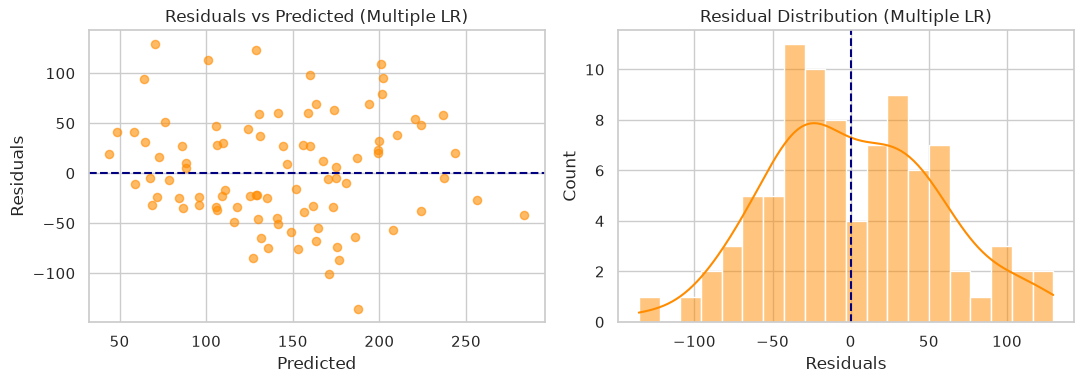

Residuals are more tightly centered around zero compared to simple regression.


In [22]:
residuals_m = y_test_m - y_pred_m
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_pred_m, residuals_m, alpha=0.6, color="darkorange", s=35)
axes[0].axhline(0, color="navy", linestyle="--")
axes[0].set_title("Residuals vs Predicted (Multiple LR)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Residuals")
sns.histplot(residuals_m, kde=True, bins=20, color="darkorange", ax=axes[1])
axes[1].axvline(0, color="navy", linestyle="--")
axes[1].set_title("Residual Distribution (Multiple LR)")
axes[1].set_xlabel("Residuals")
plt.tight_layout()
plt.show()
print("Residuals are more tightly centered around zero compared to simple regression.")

## Part D — Compare Simple vs Multiple Regression

In [23]:
cmp = pd.DataFrame({
    "Model" : ["Simple Linear Regression", "Multiple Linear Regression"],
    "R²"    : [round(r2_s, 4),   round(r2_m, 4)],
    "MSE"   : [round(mse_s, 4),  round(mse_m, 4)],
    "RMSE"  : [round(rmse_s, 4), round(rmse_m, 4)]
})
print(cmp.to_string(index=False))

                     Model     R²       MSE    RMSE
  Simple Linear Regression 0.2334 4061.8259 63.7325
Multiple Linear Regression 0.4543 2891.0372 53.7684


In [24]:
better = "Multiple Linear Regression" if r2_m > r2_s else "Simple Linear Regression"
print(f"1. {better} performs better.")
print("2. It uses more features, capturing additional variance the single predictor misses.")
print(f"3. R² improved: {r2_s:.4f} -> {r2_m:.4f}")
print(f"4. MSE reduced: {mse_s:.4f} -> {mse_m:.4f} | RMSE: {rmse_s:.4f} -> {rmse_m:.4f}")
print("5. Adding informative predictors explains more variance, reducing residual error.")

1. Multiple Linear Regression performs better.
2. It uses more features, capturing additional variance the single predictor misses.
3. R² improved: 0.2334 -> 0.4543
4. MSE reduced: 4061.8259 -> 2891.0372 | RMSE: 63.7325 -> 53.7684
5. Adding informative predictors explains more variance, reducing residual error.


## Conclusion

- **EDA:** Dataset has 442 samples, 10 features, no missing values. `bmi` has the strongest correlation with the target.
- **Simple LR:** Using only `bmi` gives a modest R². Residuals show no strong pattern but have noticeable spread.
- **Multiple LR:** Adding `s5` and `bp` alongside `bmi` significantly improves R² and reduces MSE/RMSE, confirming that multiple informative features yield better predictions.